# **Assignment 8: Multi-class Classification**

## Author: Mohammad Mehdi Zare, Mohammad Ali Olama

# Abstract

Here, we are going to perform a regression task on [Students Performance Dataset](https://www.kaggle.com/datasets/rabieelkharoua/students-performance-dataset) dataset.

Here our task is to predict grade of students (5 classes: from 0 to 4) based on other variables.

first let's read the dataset :

# Libraries

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!pip install arabic_reshaper

In [3]:
!pip install python-bidi

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 286.8/286.8 kB 16.6 MB/s eta 0:00:00


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings as wr
from matplotlib.category import UnitData

# We need these libraries for Farsi writting
import arabic_reshaper
import bidi.algorithm

wr.filterwarnings('ignore')

pd.set_option('display.max_columns', None)

In [5]:
# df_org=pd.read_csv("/content/drive/MyDrive/TEIAS/ADS/HW7/breast-cancer.csv")
df_org=pd.read_csv("/content/drive/MyDrive/TEIAS/ADS/HW8/Student_performance_data _.csv")

Now, let's have a general look at the the data.

In [6]:
df = df_org
df.head()

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0



Here our target variable is 'diagnosis'. What we want to do is to predict wether our patient has cancer or not (M - Malignant B - Benign).

We have an id column. we delete this as it may affect the performance of our models.

In [7]:
if 'StudentID	' in df.columns:
  df = df.drop('StudentID	', axis=1)

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2392 entries, 0 to 2391
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   StudentID          2392 non-null   int64  
 1   Age                2392 non-null   int64  
 2   Gender             2392 non-null   int64  
 3   Ethnicity          2392 non-null   int64  
 4   ParentalEducation  2392 non-null   int64  
 5   StudyTimeWeekly    2392 non-null   float64
 6   Absences           2392 non-null   int64  
 7   Tutoring           2392 non-null   int64  
 8   ParentalSupport    2392 non-null   int64  
 9   Extracurricular    2392 non-null   int64  
 10  Sports             2392 non-null   int64  
 11  Music              2392 non-null   int64  
 12  Volunteering       2392 non-null   int64  
 13  GPA                2392 non-null   float64
 14  GradeClass         2392 non-null   float64
dtypes: float64(3), int64(12)
memory usage: 280.4 KB


Also, let's have a look at statistics of numerical features.

In [9]:
df.describe()

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
count,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000
mean,2196.500000,16.468645,0.510870,0.877508,1.746237,9.771992,14.541388,0.301421,2.122074,0.383361,0.303512,0.196906,0.157191,1.906186,2.983696
std,690.655244,1.123798,0.499986,1.028476,1.000411,5.652774,8.467417,0.458971,1.122813,0.486307,0.459870,0.397744,0.364057,0.915156,1.233908
min,1001.000000,15.000000,0.000000,0.000000,0.000000,0.001057,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1598.750000,15.000000,0.000000,0.000000,1.000000,5.043079,7.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.174803,2.000000
50%,2196.500000,16.000000,1.000000,0.000000,2.000000,9.705363,15.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,1.893393,4.000000
75%,2794.250000,17.000000,1.000000,2.000000,2.000000,14.408410,22.000000,1.000000,3.000000,1.000000,1.000000,0.000000,0.000000,2.622216,4.000000
max,3392.000000,18.000000,1.000000,3.000000,4.000000,19.978094,29.000000,1.000000,4.000000,1.000000,1.000000,1.000000,1.000000,4.000000,4.000000


is there any null value? No!

In [10]:
print(df.isnull().sum())

StudentID            0
Age                  0
Gender               0
Ethnicity            0
ParentalEducation    0
StudyTimeWeekly      0
Absences             0
Tutoring             0
ParentalSupport      0
Extracurricular      0
Sports               0
Music                0
Volunteering         0
GPA                  0
GradeClass           0
dtype: int64


And now, let's plot correlation heatmap of numerical features.

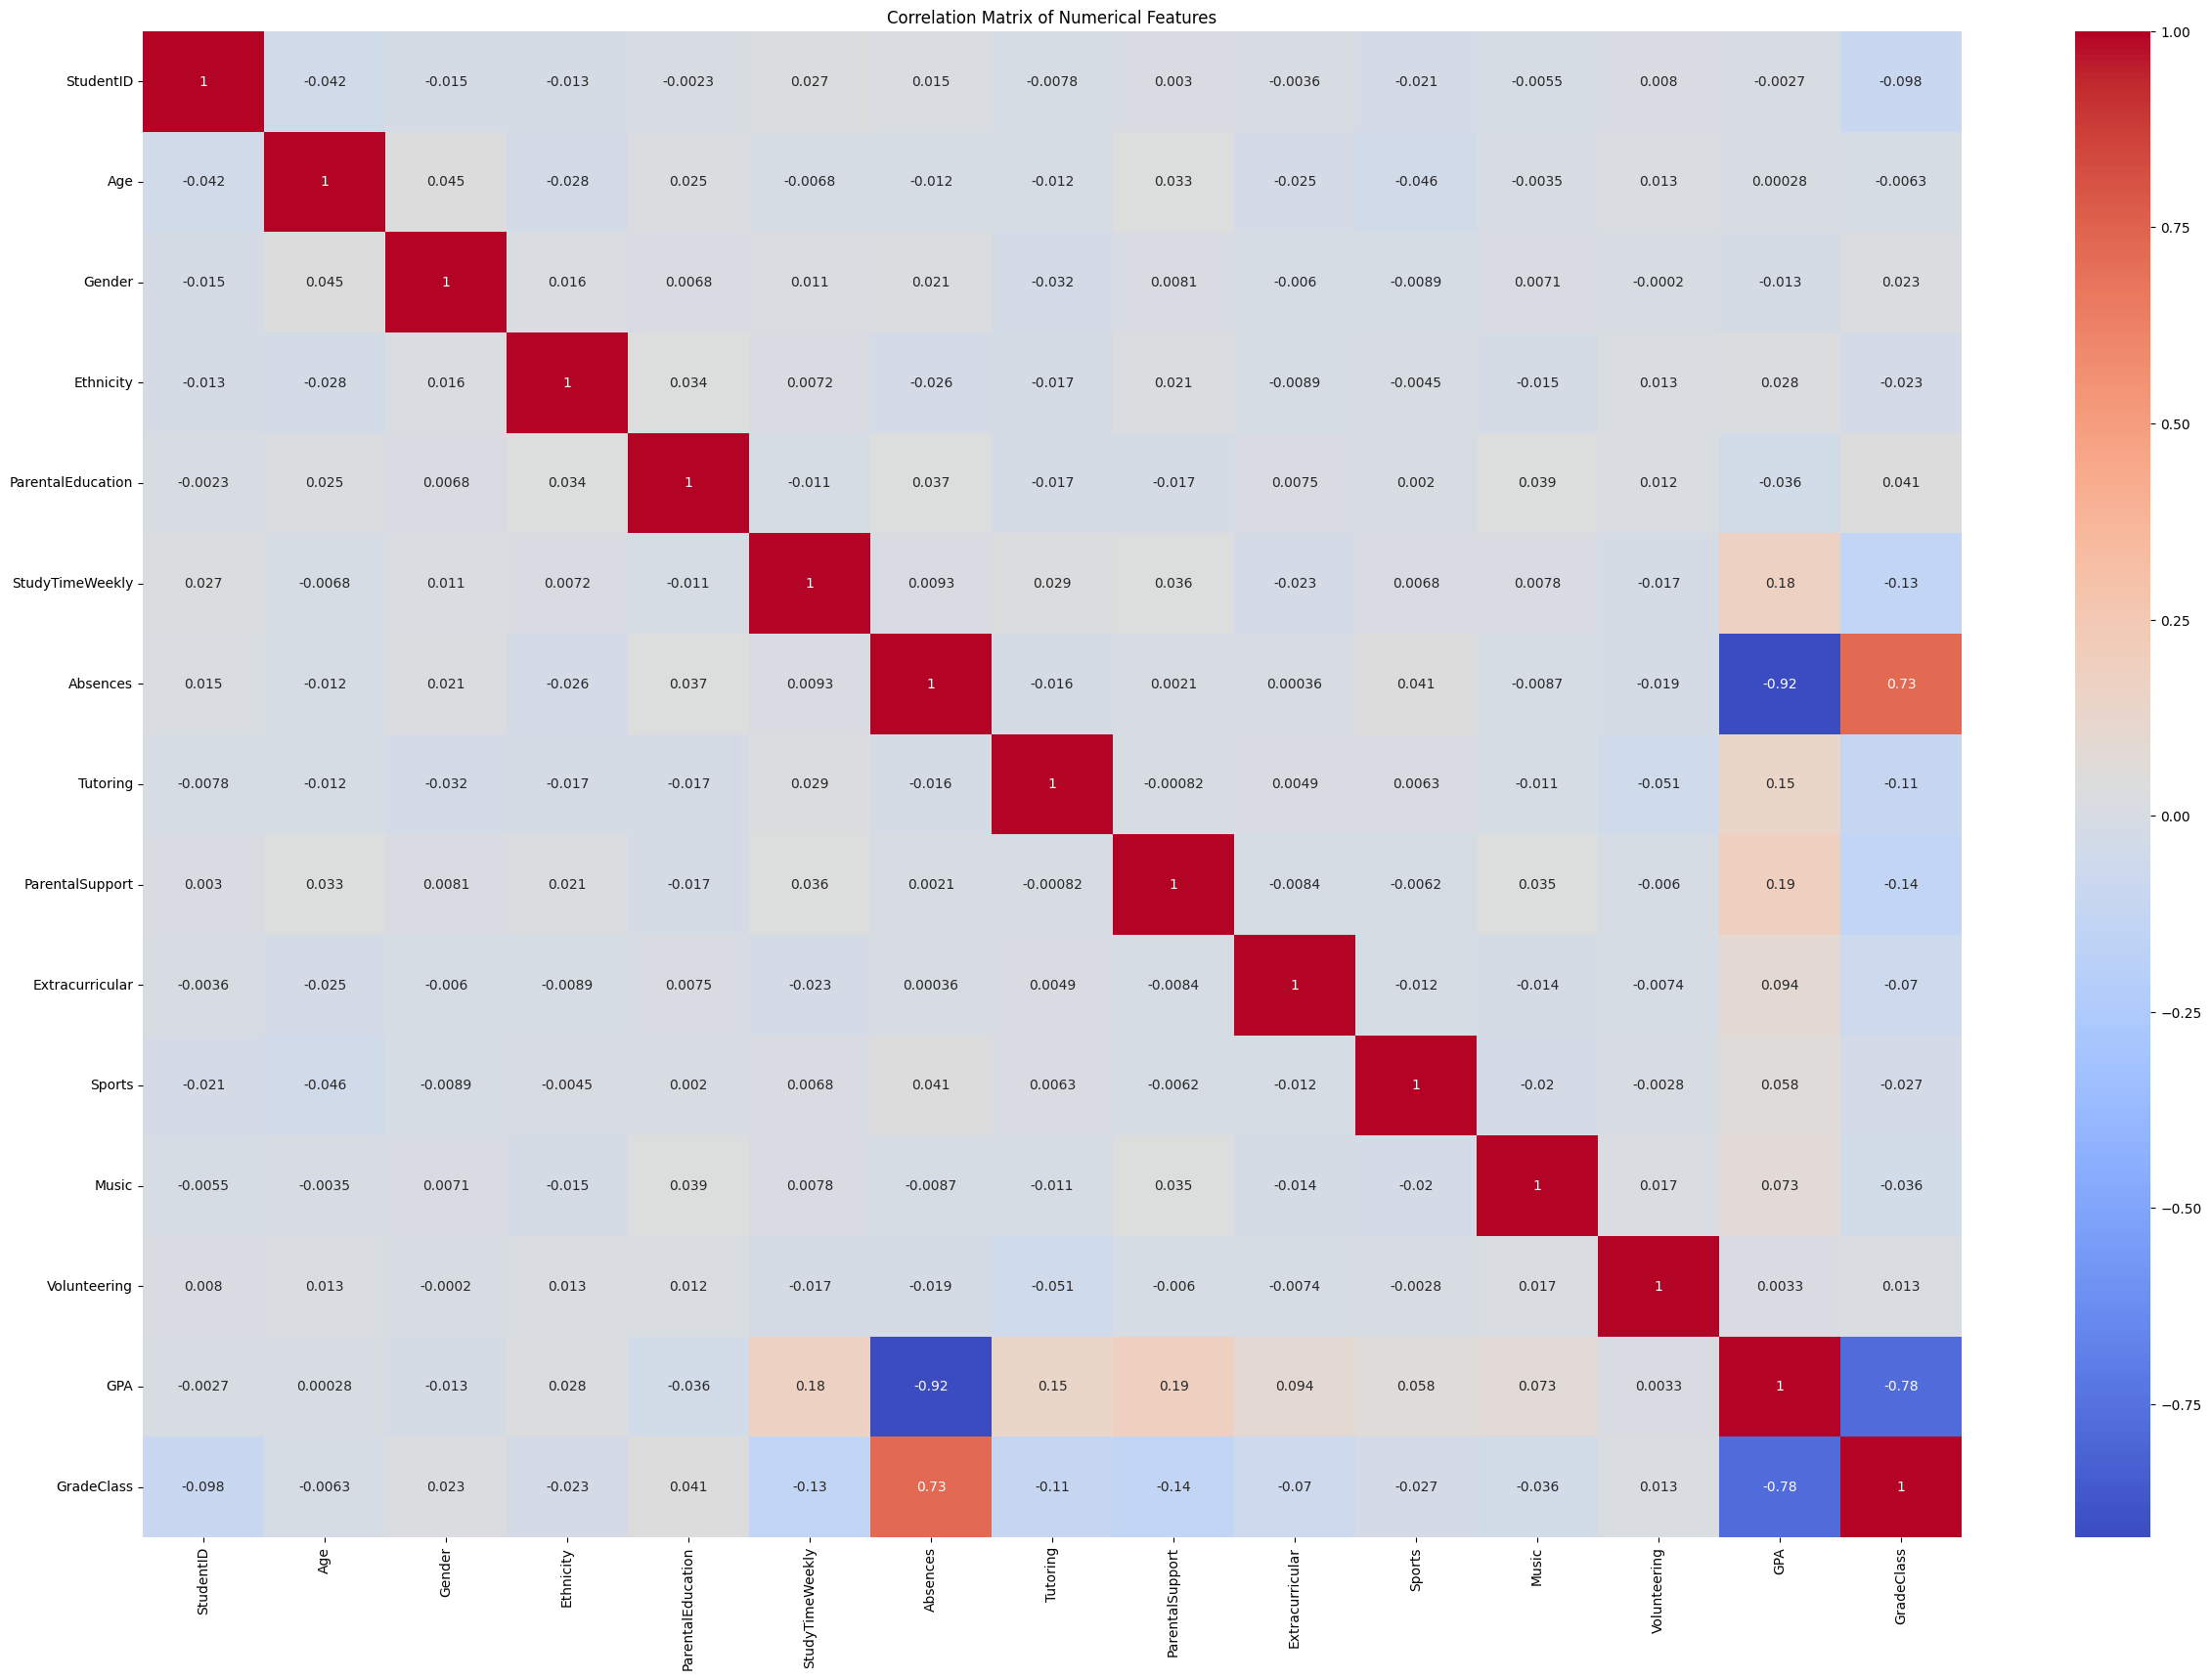

In [11]:
# Select only numerical features for correlation analysis
numerical_features = df.select_dtypes(include=np.number)

# Calculate the correlation matrix
correlation_matrix = numerical_features.corr()

# Create a heatmap
plt.figure(figsize=(30, 20))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix of Numerical Features')
plt.show()

The dataset seems to have shomehow a linear correlation between each column and the target column.

## Pre Proccessing

Our task is to predict 'Diagnosis'.

First, let's split the dataset:

In [12]:

from sklearn.model_selection import train_test_split

X = df.drop('GradeClass', axis=1)
y = df['GradeClass']

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)



### Normalization/Stadardization
we will normalize numerical columns to have a similar range.

It is important to split the dataset before normalization, to avoid any data leakage from test set into training set.


In [13]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


# Methods

## SVM

In [14]:
from sklearn.svm import SVC
from sklearn.metrics import f1_score

# Create an SVM model
svm_model = SVC(kernel='linear', decision_function_shape='ovr')  # 'ovr' for multiclass
svm_model.fit(X_train, y_train)
y_pred = svm_model.predict(X_test)

# Evaluate the model using F1-score
f1 = f1_score(y_test, y_pred, average='weighted')  # Use weighted average for multiclass

# Print the F1-score
print(f"F1-Score: {f1}")

# Check if F1-score is above 2.5/number_of_classes
num_classes = len(np.unique(y))
if f1 > 2.5 / num_classes:
    print("F1-score is above the threshold. {}".format(2.5 / num_classes))
else:
    print("F1-score is below the threshold. {}".format(2.5 / num_classes))

F1-Score: 0.8007248664404069
F1-score is above the threshold. 0.5


## Multi logistic regression


### multinomial approach

In [15]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(multi_class='multinomial') #multinomial for multi-class
logistic_model.fit(X_train, y_train)


# Make predictions on the test set
y_pred = logistic_model.predict(X_test)


# Evaluate the model using F1-score
f1 = f1_score(y_test, y_pred, average='weighted')

# Print the F1-score
print(f"F1-Score (Logistic Regression): {f1}")

# Check if F1-score is above 2.5/number_of_classes
num_classes = len(np.unique(y))
if f1 > 2.5 / num_classes:
    print("F1-score is above the threshold. {}".format(2.5 / num_classes))
else:
    print("F1-score is below the threshold. {}".format(2.5 / num_classes))

F1-Score (Logistic Regression): 0.6783527156057383
F1-score is above the threshold. 0.5


### ovr technique

In [16]:

logistic_model_ovr = LogisticRegression(multi_class='ovr')  # ovr for multi-class
logistic_model_ovr.fit(X_train, y_train)

# Make predictions on the test set
y_pred_ovr = logistic_model_ovr.predict(X_test)

# Evaluate the model using F1-score
f1_ovr = f1_score(y_test, y_pred_ovr, average='weighted')

# Print the F1-score
print(f"F1-Score (Logistic Regression with OVR): {f1_ovr}")

# Check if F1-score is above 2.5/number_of_classes
num_classes = len(np.unique(y))
if f1_ovr > 2.5 / num_classes:
    print("F1-score is above the threshold. {}".format(2.5 / num_classes))
else:
    print("F1-score is below the threshold. {}".format(2.5 / num_classes))

F1-Score (Logistic Regression with OVR): 0.5737081575416412
F1-score is above the threshold. 0.5


### log loss

In [17]:

from sklearn.metrics import log_loss

y_pred_proba = logistic_model.predict_proba(X_test)
logloss = log_loss(y_test, y_pred_proba)
print(f"Log Loss: {logloss}")

y_pred_proba_ovr = logistic_model_ovr.predict_proba(X_test)
logloss_ovr = log_loss(y_test, y_pred_proba_ovr)
print(f"Log Loss (OVR): {logloss_ovr}")

Log Loss: 0.8001519811539601
Log Loss (OVR): 0.8723289346106632


## Multiclass KNN

In [18]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV

# Create a KNN model
knn_model = KNeighborsClassifier()

# Define the parameter grid for grid search
param_grid = {
    'n_neighbors': [3, 5, 7, 9 , 11 , 13 , 15 , 17 , 19],  # Number of neighbors to consider
    'weights': ['uniform', 'distance'],  # Weighting scheme for neighbors
}

# Create a GridSearchCV object
grid_search = GridSearchCV(knn_model, param_grid, cv=5, scoring='f1_weighted')
grid_search.fit(X_train, y_train)

# Print the best parameters found by the grid search
print("Best parameters found by grid search:", grid_search.best_params_)

# Get the best model from the grid search
best_knn_model = grid_search.best_estimator_

# Make predictions on the test set
y_pred = best_knn_model.predict(X_test)

# Evaluate the model using F1-score
f1 = f1_score(y_test, y_pred, average='weighted')

# Print the F1-score
print(f"F1-Score (KNN with Grid Search): {f1}")

# Check if F1-score is above 2.5/number_of_classes
num_classes = len(np.unique(y))
if f1 > 2.5 / num_classes:
    print("F1-score is above the threshold {}.".format(2.5 / num_classes))
else:
    print("F1-score is below the threshold {}.".format(2.5 / num_classes))



Best parameters found by grid search: {'n_neighbors': 13, 'weights': 'uniform'}
F1-Score (KNN with Grid Search): 0.5993631354530354
F1-score is above the threshold 0.5.


## Decision Tree


In [19]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier()
dt_model.fit(X_train, y_train)


# Make predictions on the test set
y_pred = dt_model.predict(X_test)

# Evaluate the model using F1-score
f1 = f1_score(y_test, y_pred, average='weighted')

# Print the F1-score
print(f"F1-Score (Decision Tree): {f1}")

# Check if F1-score is above 2.5/number_of_classes
num_classes = len(np.unique(y))
if f1 > 2.5 / num_classes:
    print("F1-score is above the threshold {}.".format(2.5 / num_classes))
else:
    print("F1-score is below the threshold {}.".format(2.5 / num_classes))

F1-Score (Decision Tree): 0.9223117986569392
F1-score is above the threshold 0.5.


## Boosting

### XGBoost

In [20]:
import xgboost as xgb
from sklearn.metrics import accuracy_score

# Create an XGBoost model
xgb_model = xgb.XGBClassifier()
xgb_model.fit(X_train, y_train)


# Make predictions on the test set
y_pred = xgb_model.predict(X_test)


# Evaluate the model using F1-score
f1 = f1_score(y_test, y_pred, average='weighted')

# Print the F1-score
print(f"F1-Score (XGBoost): {f1}")

# Check if F1-score is above 2.5/number_of_classes
num_classes = len(np.unique(y))
if f1 > 2.5 / num_classes:
    print("F1-score is above the threshold {}.".format(2.5 / num_classes))
else:
    print("F1-score is below the threshold {}.".format(2.5 / num_classes))

F1-Score (XGBoost): 0.9158792618805842
F1-score is above the threshold 0.5.


### Light GBM

In [21]:
import lightgbm as lgb

# Create a LightGBM model
lgb_model = lgb.LGBMClassifier()
lgb_model.fit(X_train, y_train)

# Make predictions on the test set
y_pred = lgb_model.predict(X_test)

# Evaluate the model using F1-score
f1 = f1_score(y_test, y_pred, average='weighted')

# Print the F1-score
print(f"F1-Score (LightGBM): {f1}")

# Check if F1-score is above 2.5/number_of_classes
num_classes = len(np.unique(y))
if f1 > 2.5 / num_classes:
    print("F1-score is above the threshold {}.".format(2.5 / num_classes))
else:
    print("F1-score is below the threshold {}.".format(2.5 / num_classes))

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000695 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 836
[LightGBM] [Info] Number of data points in the train set: 1913, number of used features: 14
[LightGBM] [Info] Start training from score -3.113777
[LightGBM] [Info] Start training from score -2.162800
[LightGBM] [Info] Start training from score -1.832843
[LightGBM] [Info] Start training from score -1.763414
[LightGBM] [Info] Start training from score -0.675017
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[Lig

### Ada boost

In [22]:
from sklearn.ensemble import AdaBoostClassifier

# Create an AdaBoost model
ada_model = AdaBoostClassifier()
ada_model.fit(X_train, y_train)

# Make predictions on the test set
y_pred = ada_model.predict(X_test)

# Evaluate the model using F1-score
f1 = f1_score(y_test, y_pred, average='weighted')

# Print the F1-score
print(f"F1-Score (AdaBoost): {f1}")

# Check if F1-score is above 2.5/number_of_classes
num_classes = len(np.unique(y))
if f1 > 2.5 / num_classes:
    print("F1-score is above the threshold {}.".format(2.5 / num_classes))
else:
    print("F1-score is below the threshold {}.".format(2.5 / num_classes))

F1-Score (AdaBoost): 0.5181605201406481
F1-score is above the threshold 0.5.


The performance is terrible. Let's perform a gridsearch to see if it would improve the Adaboost:

In [23]:
# Create an AdaBoost model
ada_model = AdaBoostClassifier()

# Define the parameter grid for grid search
param_grid = {
    'n_estimators': [50, 100, 150, 200],  # Number of weak learners
    'learning_rate': [0.01, 0.03 , 0.1, 0.3, 1],  # Learning rate
    'algorithm': ['SAMME', 'SAMME.R'] # algorithm
}

# Create a GridSearchCV object
grid_search = GridSearchCV(ada_model, param_grid, cv=5, scoring='f1_weighted')
grid_search.fit(X_train, y_train)

# Print the best parameters found by the grid search
print("Best parameters found by grid search:", grid_search.best_params_)

# Get the best model from the grid search
best_ada_model = grid_search.best_estimator_

# Make predictions on the test set
y_pred = best_ada_model.predict(X_test)

# Evaluate the model using F1-score
f1 = f1_score(y_test, y_pred, average='weighted')

# Print the F1-score
print(f"F1-Score (AdaBoost with Grid Search): {f1}")

# Check if F1-score is above 2.5/number_of_classes
num_classes = len(np.unique(y))
if f1 > 2.5 / num_classes:
    print("F1-score is above the threshold {}.".format(2.5 / num_classes))
else:
    print("F1-score is below the threshold {}.".format(2.5 / num_classes))

Best parameters found by grid search: {'algorithm': 'SAMME', 'learning_rate': 0.1, 'n_estimators': 150}
F1-Score (AdaBoost with Grid Search): 0.9209604710045562
F1-score is above the threshold 0.5.


A huge improvement is gained through hyper-parameter tuning!

**Please explain how KNN and decision trees can be extended to multi-label classification problems.**


We can consider a multi-label classificcation (with $K$ labels) as $K$ distinct binary classification problem, where existance of each label is considered as a binary classificatiob problem. Thus, we can build a distinct classifiers (KNN, Decision Tree, etc.) for each label seperately ($K$ classifiers in total). The $i$th classifier will predict if the the sample belongs to the $i$th class or not (the $i$th label is true or false)
